# Exercise 52 – Overfitting and weight decay

**Week 10 · Training neural networks**

The data are a straight line $y = x + 0.5$ plus Gaussian noise. A linear model
– which "knows" the right functional form – is compared with a flexible
neural network that does not. The network can bend to fit the noise
(overfitting); weight decay (an $L_2$ penalty on the weights) pushes it back
towards simpler functions.

In [1]:
import matplotlib.pyplot as plt
import torch
from torch import nn

from comphy.models import MLP
from comphy.plotting import setup_axes
from comphy.training import fit

torch.manual_seed(0)
x_train = torch.rand(32) * 6 - 2
y_train = 1.0 * x_train + 0.5 + 0.5 * torch.randn(32)
xs = torch.linspace(-2, 4, 300)


class Line(nn.Module):
    """y = w x + b - the model that knows the answer is a straight line."""

    def __init__(self):
        super().__init__()
        self.w = nn.Parameter(torch.randn(()))
        self.b = nn.Parameter(torch.randn(()))

    def forward(self, x):
        return self.w * x + self.b


def show(ax, title):
    ax.scatter(x_train, y_train, color="C0", s=15, zorder=3)
    setup_axes(ax, xlim=(-2.25, 4.25), ylim=(-2.25, 4.25), title=title)

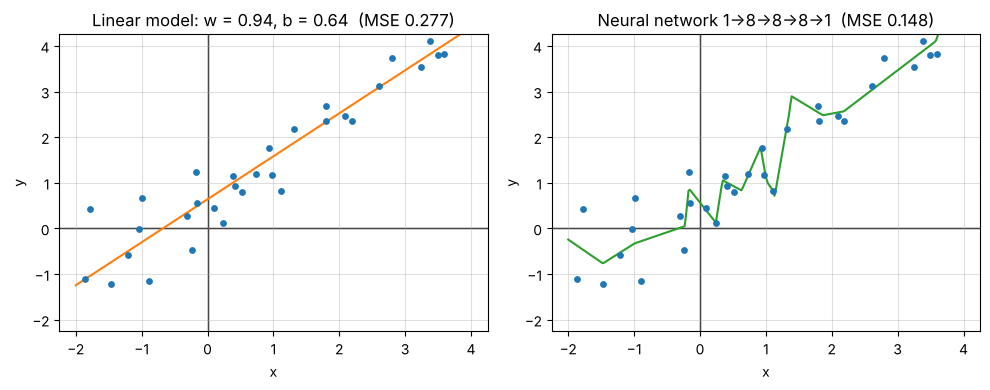

In [2]:
line = Line()
net = MLP(hidden=(8, 8, 8), activation="relu")
loss_line = fit(line, x_train, y_train, steps=10_000)[-1]
loss_net = fit(net, x_train, y_train, steps=10_000)[-1]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
with torch.no_grad():
    axes[0].plot(xs, line(xs), color="C1")
    axes[1].plot(xs, net(xs), color="C2")
show(axes[0], f"Linear model: w = {line.w.item():.2f}, b = {line.b.item():.2f}  (MSE {loss_line:.3f})")
show(axes[1], f"Neural network 1→8→8→8→1  (MSE {loss_net:.3f})")
fig.tight_layout()
plt.show()

The network reaches a *lower* training error than the true model – a sign
that it is fitting the noise.

## Effect of weight decay
Four networks with different random initialisation for each weight-decay
strength.

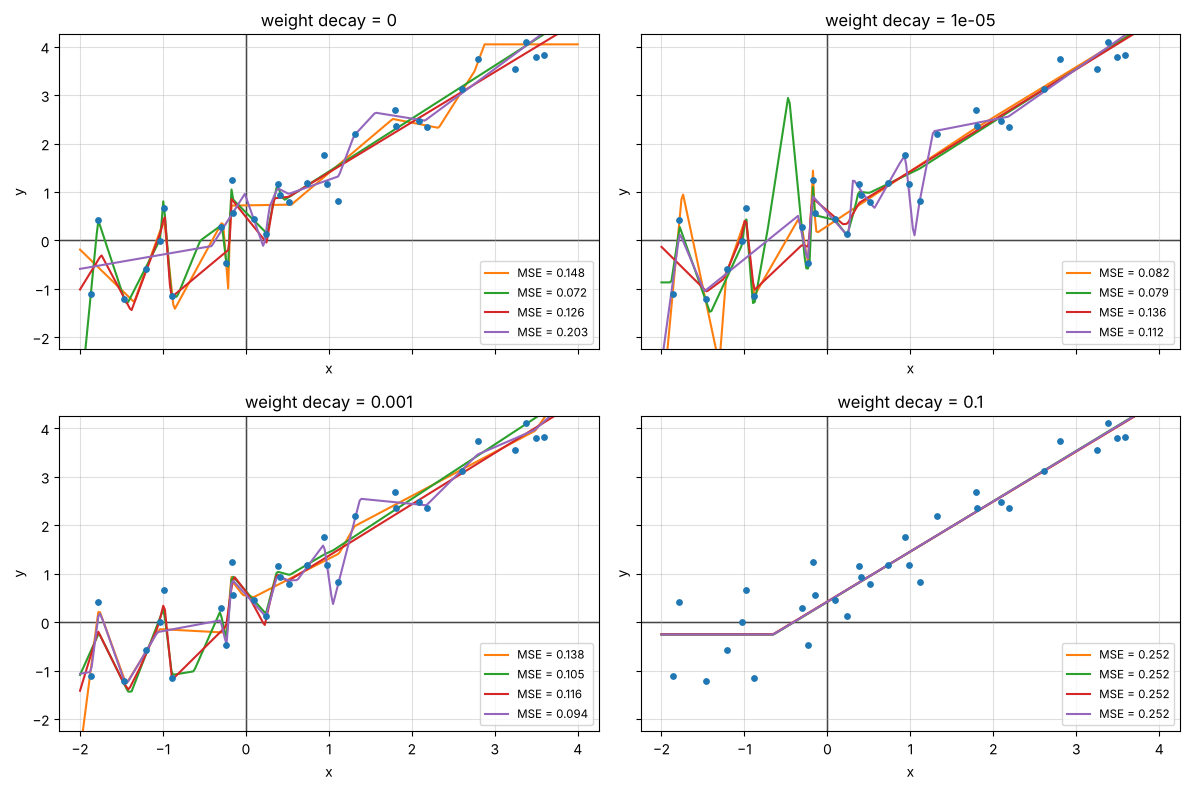

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for ax, decay in zip(axes.flat, [0, 1e-5, 1e-3, 1e-1]):
    for seed in range(4):
        torch.manual_seed(seed)
        model = MLP(hidden=(8, 8, 8), activation="relu")
        loss = fit(model, x_train, y_train, steps=4000, weight_decay=decay)[-1]
        with torch.no_grad():
            ax.plot(xs, model(xs), color=f"C{seed + 1}", label=f"MSE = {loss:.3f}")
    show(ax, f"weight decay = {decay:g}")
    ax.legend(loc="lower right", fontsize="small")
fig.tight_layout()
plt.show()

Small weight decay ($10^{-5}$, $10^{-3}$) leaves the wiggly, overfitted
curves almost unchanged. With a strong penalty (0.1) all four networks end up
with the same simple function – a straight line that flattens out on the
left – instead of chasing individual points. The training error goes up, but
the result no longer depends on the initialisation or the noise.